## **CMIP Data**: Analysis with Julia

![Slide 1](Slides/1.jpg)

In [1]:
print("Hello World")

Hello World

![Slide 1](Slides/2.jpg)

![Slide 1](Slides/3.jpg)

### **Example JIT**: Distance Calculation
Calculate the eucledian distance on two vectors with 10 Mio elements ($d=\sqrt{\sum(a_i-b_i)^2}$).
1. Using native python
2. Using numpy (precompiled functions in C)
3. Using native julia
4. Using native Julia with macros

In [1]:
using Pkg
Pkg.activate(".")
# Pkg.add(["BenchmarkTools", "PythonCall"])
# Pkg.instantiate()

using BenchmarkTools # Package for evaluating execution speed
using PythonCall # Package that allows to call Python from Julia (loads numpy library as specified in CondaPkg.toml)

np = pyimport("numpy");

  Activating project at `c:\Users\timauc002\Documents\GitHub\Fresh_eyes\Julia`
    CondaPkg Found dependencies: C:\Users\timauc002\Documents\GitHub\Fresh_eyes\Julia\CondaPkg.toml
    CondaPkg Found dependencies: C:\Users\timauc002\.julia\packages\CondaPkg\Pc7ZA\CondaPkg.toml
    CondaPkg Found dependencies: C:\Users\timauc002\.julia\packages\PythonCall\trYos\CondaPkg.toml
    CondaPkg Resolving changes
             + intake-esgf
             + libpython
             + netcdf4
             + numpy
             + openssl
             + python
             + xarray
    CondaPkg Initialising pixi
             │ C:\Users\timauc002\.julia\artifacts\6cd2217b3e33a22947fb8d4194f79fd44c7dc25f\bin\pixi.exe
             │ init
             │ --format pixi
             └ c:\Users\timauc002\Documents\GitHub\Fresh_eyes\Julia\.CondaPkg
Created C:\Users\timauc002\Documents\GitHub\Fresh_eyes\Julia\.CondaPkg\pixi.toml
    CondaPkg Wrote c:\Users\timauc002\Documents\GitHub\Fresh_eyes\Julia\.CondaPkg\pixi.

In [2]:
# Native Python Function (Runs in Python's bytecode interpreter)
@pyexec """
def euclidean_native_py(x, y):
    total = 0.0
    for i in range(len(x)):
        diff = x[i] - y[i]
        total += diff * diff
    return total ** 0.5
""" => euclidean_native_py

# Native Julia Function (Plain loop, JIT-compiled to native CPU machine code)
function euclidean_native_jl(x, y)
    total = 0.0
    for i in eachindex(x, y)
        diff = x[i] - y[i]
        total += diff * diff
    end
    return sqrt(total)
end

# Native Julia Function (Plain loop, JIT-compiled to native CPU machine code)
function euclidean_native_jl_fast(x, y)
    total = 0.0
    # @ is a macro that optimizes the compilation of the loop
    # @inbound tells the compiler to skip bounds checking for array indexing, which can improve performance
    # @simd, Single Instruction, Multiple Data, lets the compiler parallelize the operation
    @inbounds @simd for i in eachindex(x, y)
        diff = x[i] - y[i]
        total += diff * diff
    end
    return sqrt(total)
end;

In [3]:
# create random array of length N with Float64 values between 0 and 1
N = 5_000_000
a_jl = rand(Float64, N)
b_jl = rand(Float64, N)

# Convert data into Python list and NumPy array formats
a_pylist = pylist(a_jl);       b_pylist = pylist(b_jl);
a_numpy  = np.array(a_jl);     b_numpy  = np.array(b_jl);

# @btime is a macro from BenchmarkTools.jl that measures the execution time of a function call
println("1. Native Python (Interpreted for-loop):")
@btime $euclidean_native_py($a_pylist, $b_pylist)

println("\n2. Python + NumPy (Pre-compiled C library):")
@btime $np.linalg.norm($a_numpy - $b_numpy)

println("\n3. Native Julia (Pure Julia for-loop, JIT compiled):")
@btime euclidean_native_jl($a_jl, $b_jl)

println("\n4. Native Julia (Optimized for-loop, JIT compiled):")
@btime euclidean_native_jl_fast($a_jl, $b_jl);

1. Native Python (Interpreted for-loop):
  420.978 ms (2 allocations: 32 bytes)

2. Python + NumPy (Pre-compiled C library):
  44.824 ms (9 allocations: 176 bytes)

3. Native Julia (Pure Julia for-loop, JIT compiled):
  5.721 ms (0 allocations: 0 bytes)

4. Native Julia (Optimized for-loop, JIT compiled):
  3.832 ms (0 allocations: 0 bytes)


**Things to Notice**
1. **Native Python is slowest**: As expected, the pure Python loop takes the longest because the CPython interpreter has to check variable types and create new float objects in memory on every single iteration.
2. **Native Julia is even faster than NumPy**: even though NumPy also used pre-compiled C code, it is slower than Julia, becuase it evaluates the function `np.linalg.norm(a-b)` in two steps. First it runs the $a-b$ statement and writes it temporarily into RAM (9 allocations), then it runs the NumPy function. This extra step is what makes it slower than Julia which executes everything as a single pass without allocating temporary arrays. 
3. **@inbound and @simd**: both optimization speed up the Julia implementation compared to the basic Julia implementation without macros.
4. **Warm-Up**: The very first time you run a Julia function, there is a brief pause while Julia's JIT compiler translates the code into native machine instructions. The @btime macro excludes this one-time compilation overhead by executing an untimed warm-up run first and then reporting the minimum execution time across multiple runs.

### **CMIP Data Analysis**: Climate Stripes
**Packages**
* **Rasters**: Julia package for labeled multidimensional array and geospatial raster manipulation.
* **NCDatasets**: Reading, writing, and inspecting NetCDF files.
* **Dates**: Handling calendar dates, timestamps, and time intervals.
* **Statistics**: Statistical operations like `mean` and `std`.
* **CairoMakie**: Visualizing data.
* **GeoMakie**: Cartographic extension for Makie.

In [4]:
# Pkg.add(["Rasters", "NCDatasets", "Dates", "Statistics"])
# Pkg.add(["CairoMakie", "GeoMakie"])

using Rasters, Dates, Statistics, NCDatasets
using CairoMakie, GeoMakie

#### Load Data

In [5]:
intake_esgf = pyimport("intake_esgf")

# Search and download (reuses the files in ~/.esgf if already there)
catalog = intake_esgf.ESGFCatalog()     # don't call this `cat`: it would hide Julia's cat()
catalog.search(
    project       = "CMIP6",
    experiment_id = pylist(["historical", "ssp585"]),
    source_id     = "ACCESS-CM2",
    variable_id   = "tas",
    frequency     = "mon",
    variant_label = "r1i1p1f1",
    file_end      = "2100-12",
)
paths = catalog.to_path_dict()

# Convert to a Julia Dict: "historical" => [file, ...], "ssp585" => [file, ...]
# (Python keys look like "CMIP.historical", so keep only the part after the dot)
files = Dict(
    pyconvert(String, k.split(".")[-1]) => [pyconvert(String, pystr(p)) for p in v]
    for (k, v) in paths.items())

Searching indices ---------------------------------------- 100% 0:00:00
Get file information ---------------------------------------- 100% 0:00:00


<frozen importlib._bootstrap>:488: Warning: OpenSSL 3's legacy provider failed to load. Legacy algorithms will not be available. If you need those algorithms, check your OpenSSL configuration.
c:\Users\timauc002\Documents\GitHub\Fresh_eyes\Julia\.CondaPkg\.pixi\envs\default\Lib\site-packages\intake_esgf\catalog.py:936: UserWarning: You are searching for project='CMIP6' with at least one STAC-based index enabled. While republishing CMIP6 data to STAC is underway and may work well, we have found a publishing error that affects many records. You may see some unexpected `member_id` fields. Temporarily, we recommend disabling these indices for work with CMIP6:
intake_esgf.conf.set(indices={'discovery.east.esgf.io':False,'discovery.west.esgf.io': False})
  warnings.warn(


Dict{String, Vector{String}} with 2 entries:
  "historical" => ["C:\\Users\\timauc002\\.esgf\\CMIP6\\CMIP\\CSIRO-ARCCSS\\ACC…
  "ssp585"     => ["C:\\Users\\timauc002\\.esgf\\CMIP6\\ScenarioMIP\\CSIRO-ARCC…

In [6]:
loadtas(fs) = cat([read(Raster(f; name=:tas, lazy=true)[Ti=Where(t -> 1979 <= year(t) <= 2025)])
                   for f in fs]...; dims=Ti)
hist = modify(Array{Float32}, loadtas(files["historical"]))
ssp  = modify(Array{Float32}, loadtas(files["ssp585"]))
tas_raw = cat(hist, ssp; dims=Ti)

┌ 192×144×564 Raster{Float32, 3} tas ┐
├────────────────────────────────────┴─────────────────────────────────── dims ┐
  ↓ X Mapped{Float64} 0.9375:1.875:359.0625 ForwardOrdered Regular Intervals{Center},
  → Y Mapped{Float64} -89.375:1.25:89.375 ForwardOrdered Regular Intervals{Center},
  ↗ Ti Sampled{DateTime} [DateTime("1979-01-16T12:00:00"), …, DateTime("2025-12-16T12:00:00")] ForwardOrdered Explicit Intervals{Center}
├──────────────────────────────────────────────────────────────────── metadata ┤
  Metadata{Rasters.NCDsource} of Dict{String, Any} with 10 entries:
  "cell_methods"  => "area: time: mean"
  "coordinates"   => "height"
  "_FillValue"    => 1.0f20
  "missing_value" => 1.0f20
  "standard_name" => "air_temperature"
  "long_name"     => "Near-Surface Air Temperature"
  "units"         => "K"
  "history"       => "2019-11-08T06:41:45Z altered by CMOR: Treated scalar dime…
  "comment"       => "near-surface (usually, 2 meter) air temperature"
  "cell_measures" => "area: ar

#### Calculate Temperature Anomaly

In [7]:
tas = tas_raw .- 273.15f0
    
# Slice periods using precise end dates to ensure perfect 12-month multiples
tas_ref = tas[Ti(Where(x -> 1981 <= Dates.year(x) <= 2010))]
tas_anom = tas[Ti(Where(x -> 1979 <= Dates.year(x) <= 2025))]

nx, ny, nt_ref = size(tas_ref) # dimensions of reference period
nt_anom = size(tas_anom, 3) # time dimension of analysis period

# Reshape the 3D reference array into 4D: (Lon, Lat, Month, Year)
ref_reshaped = reshape(tas_ref.data, nx, ny, 12, nt_ref ÷ 12) # ÷ use for integer division

# Take mean across the year dimension
clim_data = mean(ref_reshaped, dims=4)

# Reshape the analysis array to match the 4D structure
anom_reshaped = reshape(tas_anom.data, nx, ny, 12, nt_anom ÷ 12)

# Subtract the monthly climatology
anom_data = anom_reshaped .- clim_data; # dim (192, 144, 12, 36) .- (192, 144, 12, 1)

# Convert back into raster file
anom_data = Raster(reshape(anom_data, nx, ny, nt_anom), dims(tas_anom))
mean_anom = mean(anom_data, dims=Ti)

┌ 192×144×1 Raster{Float32, 3} ┐
├──────────────────────────────┴───────────────────────────────────────── dims ┐
  ↓ X Mapped{Float64} 0.9375:1.875:359.0625 ForwardOrdered Regular Intervals{Center},
  → Y Mapped{Float64} -89.375:1.25:89.375 ForwardOrdered Regular Intervals{Center},
  ↗ Ti Sampled{DateTime} DateTime("2002-07-02T12:00:00"):Millisecond(2678400000):DateTime("2002-07-02T12:00:00") ForwardOrdered Explicit Intervals{Center}
├────────────────────────────────────────────────────────────────────── raster ┤
  extent: Extent(X = (0.0, 360.0), Y = (-90.0, 90.0), Ti = (DateTime("1979-01-01T00:00:00"), DateTime("2026-01-01T00:00:00")))
  crs: EPSG:4326
  mappedcrs: EPSG:4326
└──────────────────────────────────────────────────────────────────────────────┘
[:, :, 1]
   ↓ →     -89.375     -88.125     …  86.875     88.125     89.375
   0.9375    0.275573    0.318173      0.792436   0.768628   0.757774
   2.8125    0.274984    0.321145      0.79037    0.766226   0.756359
   4.6875    0.

#### Visualization Average Anomaly in Space

In [8]:
# Remove dimensions for plotting
data_matrix = dropdims(mean_anom, dims=Ti)

# Extract coordinates and data and convert into native julia arrays
lons = collect(lookup(tas_anom, X))
lats = collect(lookup(tas_anom, Y))

# Shift longitudes from [0, 360] to [-180, 180] for GeoMakie Robinson projection
split_idx = findfirst(x -> x > 180, lons)

# Shift coordinates
lons_shifted = vcat(lons[split_idx:end] .- 360, lons[1:split_idx-1]) # vertical stack -180 : + 180
# Apply shift to the dataset
data_shifted = vcat(data_matrix[split_idx:end, :], data_matrix[1:split_idx-1, :])

┌ Warning: `cat` cannot concatenate `Dimension`s, falling back to `parent` type:
│ `Ordered` lookups are misaligned at 179.0625 and 0.9375 on dimension X. 
│ 
│ To fix for `AbstractDimArray`, pass new lookup values as `cat(As...; dims=X(newlookupvals))` keyword or `dims=X()` for empty `NoLookup`.
└ @ DimensionalData C:\Users\timauc002\.julia\packages\DimensionalData\DVvD4\src\array\methods.jl:557


192×144 Matrix{Float32}:
 0.218791  0.203449  0.15148   0.103119  …  0.742488  0.749754  0.751344
 0.2188    0.202958  0.14974   0.100691     0.742914  0.751435  0.752343
 0.218848  0.203469  0.149709  0.101252     0.744302  0.752275  0.754231
 0.220067  0.203194  0.150743  0.101022     0.744888  0.753745  0.75268
 0.220798  0.202907  0.153467  0.103272     0.74546   0.753138  0.754695
 0.220412  0.203963  0.154665  0.106985  …  0.746106  0.754675  0.75451
 0.221177  0.20527   0.155398  0.109543     0.748094  0.753052  0.75629
 0.221235  0.20583   0.155682  0.114052     0.746976  0.753327  0.757107
 0.221663  0.205654  0.156184  0.11488      0.748728  0.751182  0.759404
 0.223015  0.207216  0.156903  0.117973     0.748657  0.753483  0.758913
 ⋮                                       ⋱                      
 0.218439  0.211346  0.155294  0.121564     0.747566  0.749414  0.748461
 0.218945  0.211581  0.15239   0.11998      0.746026  0.748376  0.747943
 0.219155  0.209628  0.152525  0.1168

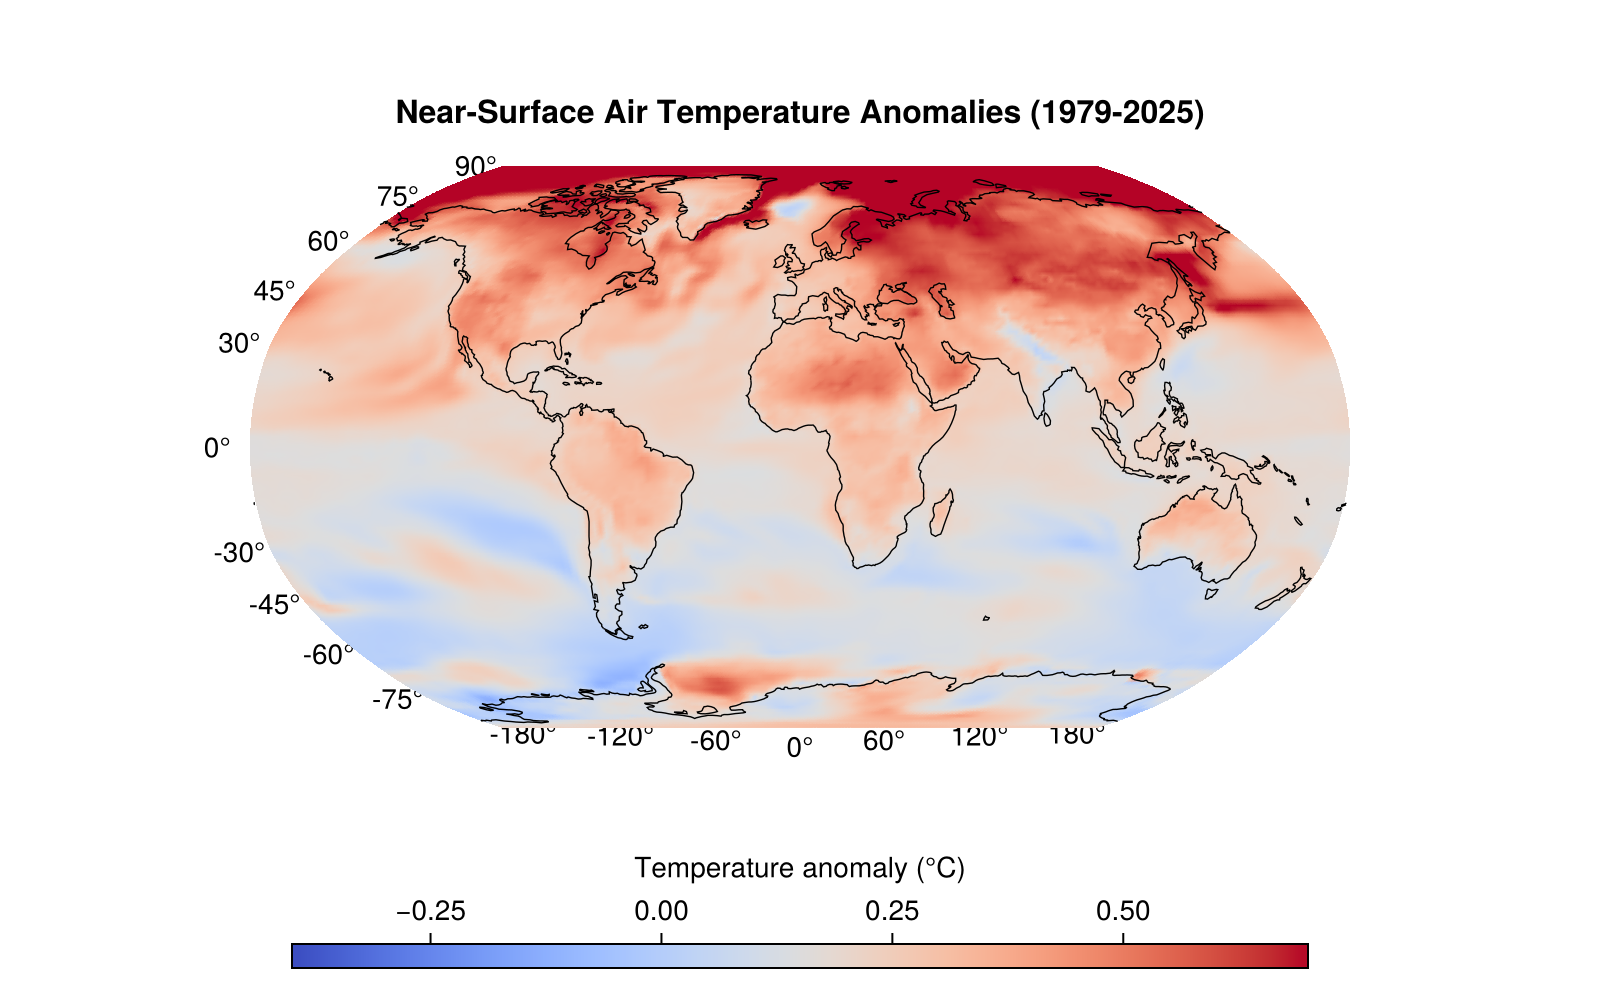

In [9]:
# Create Figure with standard Greenwich-centered projection
fig = Figure(size = (800, 500))
ga = GeoAxis( # create geographic coordinate system
    fig[1, 1];
    dest = "+proj=robin", # Robinson projection (Edges are now strictly ±180°) 
    title = "Near-Surface Air Temperature Anomalies (1979-2025)",
    titlesize = 16,
    xgridvisible = false, # hide grid lines
    ygridvisible = false
)
# Plot the surface using the shifted longitudes and data
sp = surface!(
    ga, # projection from Geoaxis
    lons_shifted, 
    lats, 
    data_shifted;
    colormap = :coolwarm,
    colorrange = (-0.4, 0.7),
    shading = NoShading
)

# add coastlines
lines!(ga, GeoMakie.coastlines(), color = :black, linewidth = 0.7)

# Add horizontal colorbar
Colorbar(
    fig[2, 1], sp; 
    vertical = false, 
    label = "Temperature anomaly (°C)", 
    width = Relative(0.7)
)

fig

#### Visualization Polar Amplification

In [10]:
# Plot temperature curve of arctiv region
# Select 65-90°N and average over lon (X) and lat (Y)
tas_65_90N = anom_data[Y(65 .. 90)]
tas_65_90N_mean = mean(tas_65_90N, dims=(X, Y))
tas_65_90N_mean = dropdims(tas_65_90N_mean, dims=(X, Y))
tas_30_60N_mean = mean(anom_data[Y(30 .. 65)], dims=(X, Y))
tas_30_60N_mean = dropdims(tas_30_60N_mean, dims=(X, Y))

time_data = collect(lookup(tas_65_90N_mean, Ti)); # Extract a standard array from the Raster data
temp_data_65_90N = collect(tas_65_90N_mean); # Extract a standard array from the Raster data
temp_data_30_60N = collect(tas_30_60N_mean); # Extract a standard array from the Raster data

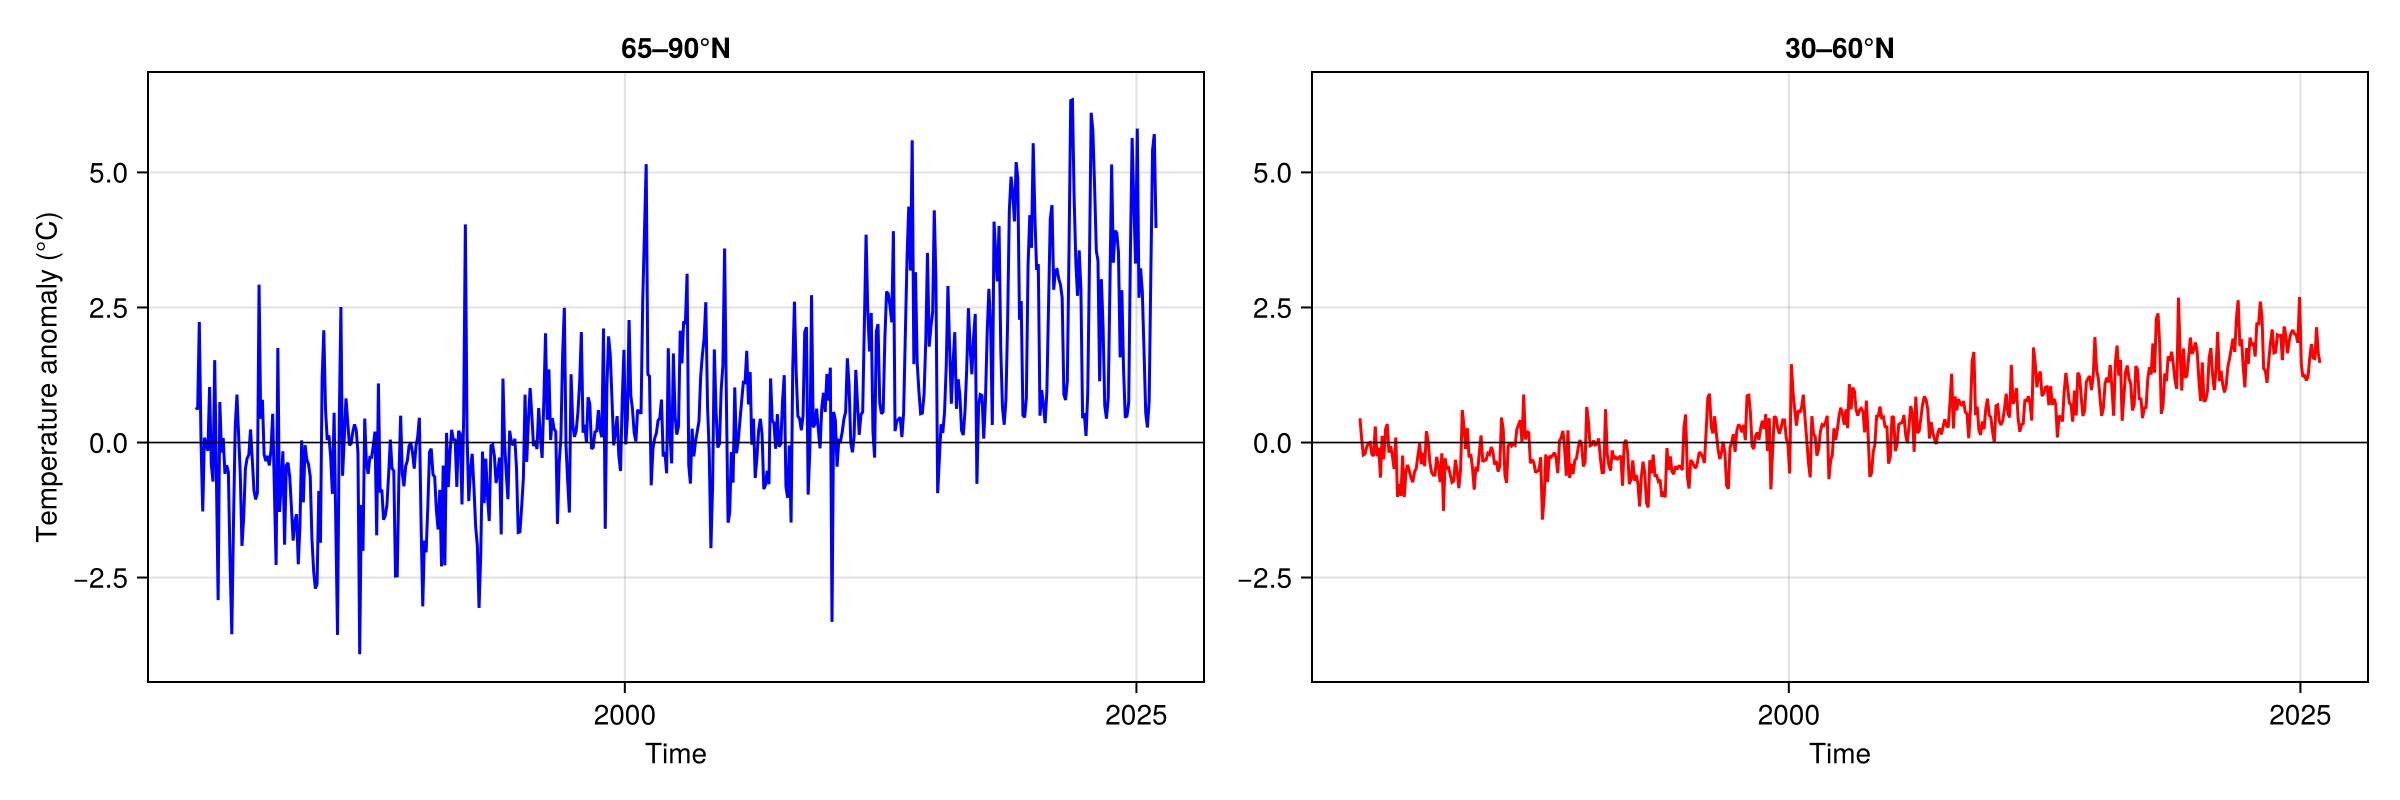

In [11]:
fig = Figure(size = (1200, 400)) # create figure canvas

# Create the first Axis in row 1, column 1 (Left)
ax1 = Axis( 
    fig[1, 1], 
    xlabel = "Time",
    ylabel = "Temperature anomaly (°C)",
    title = "65–90°N"
)

# Create the second Axis in row 1, column 2 (Right)
ax2 = Axis(
    fig[1, 2], 
    xlabel = "Time",
    title = "30–60°N"
)

# Plot data into the first axis
lines!(ax1, time_data, temp_data_65_90N, color = :blue, linewidth = 1.5)
hlines!(ax1, [0.0], color = :black, linewidth = 0.8)

# Plot data into the second axis
lines!(ax2, time_data, temp_data_30_60N, color = :red, linewidth = 1.5)
hlines!(ax2, [0.0], color = :black, linewidth = 0.8)

linkyaxes!(ax1, ax2) # sync the y-axis of all plots
display(fig);

##### Visualize Climate Stripes

In [12]:
temp_grouped = groupby(tas_65_90N, Ti => Dates.year)

┌ 47-element DimGroupByArray{Raster{Float32,3},1} ┐
├─────────────────────────────────────────────────┴─────────────── dims ┐
  ↓ Ti Sampled{Int64} [1979, …, 2025] ForwardOrdered Irregular Points
├───────────────────────────────────────────────────────────── metadata ┤
  Dict{Symbol, Any} with 1 entry:
  :groupby => :Ti=>year
├─────────────────────────────────────────────────┴───────── group dims ┐
  ↓ X, → Y, ↗ Ti
└───────────────────────────────────────────────────────────────────────┘
 1979  192×20×12 Raster
 1980  192×20×12 Raster
    ⋮  
 2025  192×20×12 Raster

In [13]:
temperature = mean.(temp_grouped)

┌ 47-element DimArray{Float32, 1} ┐
├─────────────────────────────────┴─────────────────────────────── dims ┐
  ↓ Ti Sampled{Int64} [1979, …, 2025] ForwardOrdered Irregular Points
└───────────────────────────────────────────────────────────────────────┘
 1979   0.298601
 1980  -0.95514
 1981  -0.489437
 1982  -0.0674735
 1983  -0.802693
    ⋮  
 2021   3.21668
 2022   2.86832
 2023   2.53557
 2024   2.64721
 2025   3.00792

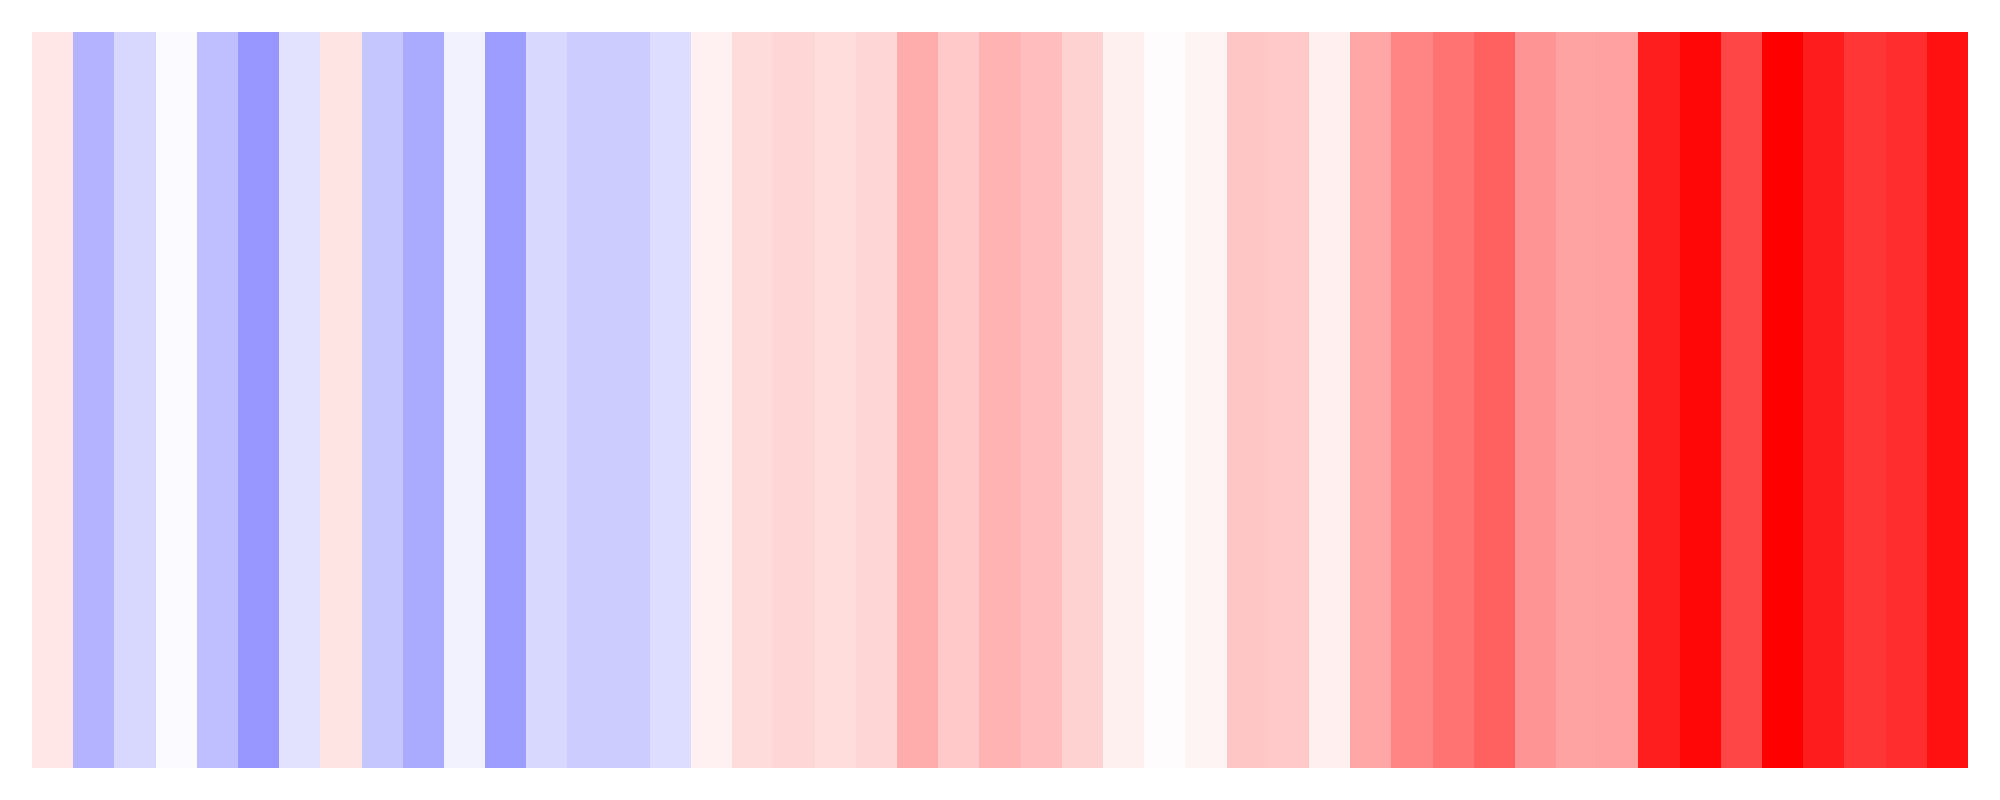

In [14]:
years = collect(lookup(temperature, Ti)) # Extract the numeric years directly from the grouped Raster
temp_values = collect(temperature) # Extract the numeric temperature values

# Get the maximum absolute anomaly for a centered color scale
limit = maximum(abs.(temp_values))

fig = Figure(size = (1000, 400))
ax = Axis(fig[1, 1])

# Remove standard plot elements
hidedecorations!(ax) # remove x and y labels
hidespines!(ax)  # remove x and y axis lines

heatmap!(
    ax, 
    years, 
    [1], # y-axis dummy value
    reshape(temp_values, :, 1); # Reshape 1D vector to an (N_years, 1) matrix
    colormap = :bwr,
    colorrange = (-limit, limit)
)

display(fig);